In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache
import matplotlib.pyplot as plt
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *

In [3]:
prefix = '/mnt/staging/'
figure_config_root = str(PREPARES / "config") + "/"
palatte_dict = load_pickle(figure_config_root+'palatte_dict')

In [4]:
from pathlib import Path


In [5]:
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache

# The manifest file is a simple JSON file that keeps track of all of
# the data that has already been downloaded onto the hard drives.
# If you supply a relative path, it is assumed to be relative to your
# current working directory.
root_path = str(PREPARES / "allen-connectivity-atlas/NEW") + "/"
result_path = root_path + 'wild-type-M2/'
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

# take a look at what we know about an experiment with a primary motor injection
# all_experiments.loc[114290938]

2992 total experiments


In [6]:
result_path_2 = str(PREPARES / "allen-connectivity-atlas/NEW/extra-M2")
mcc_extra = MouseConnectivityCache(manifest_file=Path(result_path_2) / 'manifest.json',resolution=10)


In [7]:
# Get Allen Annotation Atlas (as before)
result_path_3 = str(PREPARES / "allen-connectivity-atlas/NEW/allen-template") + "/"

mcc_allen = MouseConnectivityCache(resolution=10, manifest_file=result_path_3+'mouse_connectivity_manifest.json')
annotation_volume, meta = mcc_allen.get_annotation_volume()
print("Allen annotation atlas loaded successfully.")


Allen annotation atlas loaded successfully.


In [8]:
annotation_volume.shape

(1320, 800, 1140)

In [9]:
experiment_ids_MOs = {
    "MOs_whisker": 141603190, # wild type
    "MOs_FP": 157710335, # wild type
    # "MOs_HP": 112952510, 
    "MOs_nose": 585025284, # wild type
    "MOs_HP": 100141454, # wild type
}

experiment_ids_MOs_extra = {
                      'MOs_mouth':166082128, #Rbp4-Cre-113
                      'MOs_visual':158018630 #Gng7-Cre-971
}

In [ ]:
dict_ind = {}
dict_ind_info = {}
dict_pd = {}
dict_pd_info = {}
for key in experiment_ids_MOs:
    experiment_id = experiment_ids_MOs[key]
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    

In [ ]:
for key in experiment_ids_MOs_extra:
    experiment_id = experiment_ids_MOs_extra[key]
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc_extra.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc_extra.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info

(1200.0, 160.0)

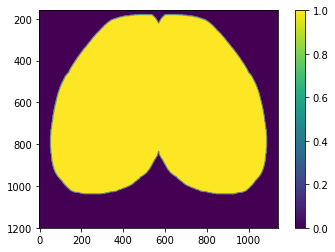

In [ ]:
# in addition to the annotation volume, you can get binary masks for individual structures
# in this case, we'll get one for the isocortex
cortex_mask, cm_info = mcc.get_structure_mask(315)

cortex_mask_mip = cortex_mask.max(axis=1)

from skimage import measure
brain_contours = measure.find_contours(cortex_mask_mip>0.5, level=0.5)

    
plt.imshow(cortex_mask_mip)
plt.colorbar()
for contour in brain_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.9)
# plt.xlim([20,436])
plt.ylim([1200,160])

### downsize

In [ ]:
import skimage
from skimage.transform import resize
from joblib import Parallel, delayed

# Downsample a single volume (z, y, x)
def downsample(vol, scale=0.5):
    return resize(vol, 
                  output_shape=tuple([int(s * scale) for s in vol.shape]),
                  preserve_range=True,
                  anti_aliasing=True).astype(vol.dtype)

# 1. Process dict_pd
# Run the downsample function on each dictionary value in parallel
downsampled_pd_values = Parallel(n_jobs=-1)(
    delayed(downsample)(matrix) for matrix in dict_pd.values()
)
# Reconstruct the dictionary
downsampled_dict_pd = dict(zip(dict_pd.keys(), downsampled_pd_values))


In [ ]:
downsampled_dict_pd['MOs_whisker'].shape

(660, 400, 570)

In [ ]:
downsampled_dict_pd.keys()

dict_keys(['MOs_whisker', 'MOs_FP', 'MOs_nose', 'MOs_HP', 'MOs_mouth', 'MOs_visual'])

In [ ]:
downsampled_dict_pd['MOs_whisker'].shape

(660, 400, 570)

In [72]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache
from skimage.transform import resize
from ipywidgets import interact, IntSlider

# --- 1. Setup: Dictionaries and Dummy Data ---

# Your dictionaries for mapping, colors, and scaling
bdp_short_dict = {'LFP':'MOs_FP','LHP':'MOs_HP','LM':'MOs_mouth','LW':'MOs_whisker',
                  'LN':'MOs_nose','LV':'MOs_visual'}

palette_dict = {'RFP': '#015EB5', 'LFP': '#ABC9E3', 'RM': '#df2f2b', 'LM': '#ee8c7d',
                'RW': '#501d8a', 'LW': '#bf8fc9', 'RHP': '#efb708', 'LHP': '#e6ff05',
                'RN': '#1c8041', 'LN': '#B0D8AA', 'RV': '#B01A5B', 'LV': '#E23E85'}

# dict_scaling_factor = {'LHP': 1.0, 'LFP': 0.792, 'LW':  0.579, 'LN':  0.579,
#                        'LV':  0.413, 'LM':  0.233}
dict_scaling_factor = {'LHP': 1.0, 'LFP': 1, 'LW':  1, 'LN':  1,
                       'LV':  1, 'LM':  1}

# For demonstration, create a dictionary of random data arrays
# In your code, you would use your actual 'downsampled_dict_pd'
print("Loading data...")


# --- 2. Combine Volumes into a Single RGB Array ---

# Create an empty 4D array to store the combined RGB volume. Shape is (slices, height, width, 3 for RGB).
combined_rgb_volume = np.zeros(downsampled_dict_pd['MOs_whisker'].shape + (3,))

# List of body parts to process
body_part_keys = ['MOs_whisker', 'MOs_HP', 'MOs_mouth', 'MOs_FP', 'MOs_visual', 'MOs_nose']

for label in body_part_keys:
    # Get the short name (e.g., 'LW' for 'MOs_whisker')
    bdp_short = next((k for k, v in bdp_short_dict.items() if v == label), None)
    if not bdp_short:
        continue

    print(f"Processing: {label} ({bdp_short})")
    
    # Get the specific color and convert from hex to an RGB tuple (e.g., (0.74, 0.56, 0.78))
    color_rgb = to_rgb(palette_dict[bdp_short])
    
    # Get the data and apply the scaling factor
    # This scales the intensity of this specific body part's projection
    scaled_data = downsampled_dict_pd[label] * dict_scaling_factor[bdp_short]
    
    # "Colorize" the grayscale data by multiplying it with its RGB color
    # We add a new axis to the scaled_data to allow broadcasting with the (3,) color vector
    colored_volume = scaled_data[..., np.newaxis] * color_rgb
    
    # Blend this new colored volume into the main volume using maximum intensity projection
    # This ensures that bright signals from different channels are overlaid correctly
    combined_rgb_volume = np.maximum(combined_rgb_volume, colored_volume)

# Ensure the final values are clipped between 0 and 1 for valid color display
combined_rgb_volume = np.clip(combined_rgb_volume, 0, 1)

print("\nAll volumes combined into a single RGB array. Ready for plotting.")

# --- 3. Create the Interactive Plotting Function ---

@interact(slice_idx=IntSlider(min=0, max=combined_rgb_volume.shape[0] - 1, step=1, value=150, description='Coronal Slice:'))
def view_slice(slice_idx):
    # Get the 2D RGB slice from your combined volume
    rgb_slice = combined_rgb_volume[slice_idx, :, :]
    
    # Calculate the corresponding slice index in the FULL-RESOLUTION atlas
    atlas_slice_idx_full = int(np.floor(slice_idx * (annotation_volume.shape[0] / combined_rgb_volume.shape[0])))
    
    # Get the 2D HIGH-RESOLUTION slice from the original annotation atlas
    annotation_slice_full = annotation_volume[atlas_slice_idx_full, :, :]
    
    # For the overlay panel, resize the RGB slice to match the atlas slice's shape
    rgb_slice_resized = resize(rgb_slice, annotation_slice_full.shape, preserve_range=True, anti_aliasing=True)

    # Plot 2: Low-res data with HIGH-RES outlines
    fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(9, 18), facecolor='black',dpi=300)
    
    colored_atlas_slice = colored_atlas_volume[slice_idx, :, :]
    ax1.imshow(colored_atlas_slice, origin='lower'); ax1.set_title('Allen Reference Atlas', color='white'); ax1.axis('off')
    for struct_id in np.unique(annotation_slice_full):
        if struct_id == 0: continue
        mask = annotation_slice_full == struct_id
        center = center_of_mass(mask)
        ax1.text(center[1], center[0], structure_map.get(struct_id, ''), ha='center', va='center', color='white', fontsize=10)
    plot_extent = [0, rgb_slice.shape[1], 0, rgb_slice.shape[0]]
    ax1.invert_yaxis();


    ax2.set_facecolor('black')
    # Define the data coordinates. We use the shape of the low-res image as the coordinate system.
    # Both the image and the contour will be mapped to this same box.
    plot_extent = [0, rgb_slice.shape[1], rgb_slice.shape[0], 0]

    # Display your low-res RGB image, telling it to fill the 'extent'
    ax2.imshow(rgb_slice, extent=plot_extent,origin='lower')
    
    # Draw the high-res contour, also telling it to fill the same 'extent'
    # Matplotlib will handle the scaling automatically.
    ax2.contour(annotation_slice_full, 
                levels=np.unique(annotation_slice_full), 
                colors='white', 
                linewidths=0.4, # You can now use a reasonable line width
                alpha=0.1,
                extent=plot_extent)
    ax2.invert_yaxis()
    plt.show()
    

Loading data...
Processing: MOs_whisker (LW)
Processing: MOs_HP (LHP)
Processing: MOs_mouth (LM)
Processing: MOs_FP (LFP)
Processing: MOs_visual (LV)
Processing: MOs_nose (LN)

All volumes combined into a single RGB array. Ready for plotting.


interactive(children=(IntSlider(value=150, description='Coronal Slice:', max=329), Output()), _dom_classes=('w…

In [61]:
# import subprocess
# from pathlib import Path
# import shutil

# # ... (all your frame generation code remains the same) ...

# # 4. Stitch frames into a movie using a direct ffmpeg call
# output_movie_path = 'brain_scan.mp4'
# temp_frame_dir = Path('./temp_frames')
# fps = 30

# print(f"Creating movie '{output_movie_path}' with a direct ffmpeg call...")

# # This is the command that will be run in the terminal
# # -r: frame rate
# # -i: input files (the %04d matches the frame numbering)
# # -vcodec: video compression format
# # -pix_fmt: pixel format required for most video players
# ffmpeg_command = [
#     'ffmpeg',
#     '-r', str(fps),
#     '-i', f'{temp_frame_dir}/frame_%04d.png',
#     '-vcodec', 'libx264',
#     '-pix_fmt', 'yuv420p',
#     output_movie_path
# ]

# # Run the command
# # We add '-y' to automatically overwrite the output file if it exists
# subprocess.run(ffmpeg_command + ['-y'], check=True)

# print("Movie created successfully!")

# # 5. Clean up temporary files
# print(f"Cleaning up temporary directory: {temp_frame_dir}")
# shutil.rmtree(temp_frame_dir)
# print("Done.")

Creating movie 'brain_scan.mp4' with a direct ffmpeg call...
Movie created successfully!
Cleaning up temporary directory: temp_frames
Done.


In [73]:
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.colors import to_rgb
# from matplotlib.gridspec import GridSpec
# from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache
# from skimage.transform import resize
# from ipywidgets import interact, IntSlider
# from scipy.ndimage import center_of_mass

# # --- 1. Setup and Data Loading ---
# bdp_short_dict = {'LFP':'MOs_FP','LHP':'MOs_HP','LM':'MOs_mouth','LW':'MOs_whisker', 'LN':'MOs_nose','LV':'MOs_visual'}
# palette_dict = {'RFP': '#015EB5', 'LFP': '#ABC9E3', 'RM': '#df2f2b', 'LM': '#ee8c7d', 'RW': '#501d8a', 'LW': '#bf8fc9', 'RHP': '#efb708', 'LHP': '#e6ff05', 'RN': '#1c8041', 'LN': '#B0D8AA', 'RV': '#B01A5B', 'LV': '#E23E85'}
# dict_scaling_factor = {'LHP': 1.0, 'LFP': 1, 'LW': 1, 'LN': 1, 'LV': 1, 'LM': 1}

# mcc = MouseConnectivityCache(resolution=10, manifest_file='connectivity/mouse_connectivity_manifest.json')
# annotation_volume_full, meta = mcc.get_annotation_volume()
# structure_tree = mcc.get_structure_tree()
# print("Allen SDK data loaded.")

# # --- 2. Pre-computation for Plots ---

# # A) Create mappings
# structure_map = structure_tree.get_id_acronym_map()
# color_map = {s['id']: [c/255.0 for c in s['rgb_triplet']] for s in structure_tree.nodes()}
# if 0 not in color_map: color_map[0] = [0, 0, 0]

# # B) Build the full 3D colored atlas volume (OPTIMIZED)
# print("Building 3D colored atlas volume...")
# max_id = max(color_map.keys())
# lookup_table = np.zeros((max_id + 1, 3))
# for struct_id, color in color_map.items():
#     lookup_table[struct_id] = color
# colored_atlas_volume = lookup_table[annotation_volume_full]
# print("Colored atlas built.")

# # C) Combine your projection data into a single RGB volume
# # Create an empty 4D array to store the combined RGB volume. Shape is (slices, height, width, 3 for RGB).
# combined_rgb_volume = np.zeros(downsampled_dict_pd['MOs_whisker'].shape + (3,))

# # List of body parts to process
# body_part_keys = ['MOs_whisker', 'MOs_HP', 'MOs_mouth', 'MOs_FP', 'MOs_visual', 'MOs_nose']

# for label in body_part_keys:
#     # Get the short name (e.g., 'LW' for 'MOs_whisker')
#     bdp_short = next((k for k, v in bdp_short_dict.items() if v == label), None)
#     if not bdp_short:
#         continue

#     print(f"Processing: {label} ({bdp_short})")
    
#     # Get the specific color and convert from hex to an RGB tuple (e.g., (0.74, 0.56, 0.78))
#     color_rgb = to_rgb(palette_dict[bdp_short])
    
#     # Get the data and apply the scaling factor
#     # This scales the intensity of this specific body part's projection
#     scaled_data = downsampled_dict_pd[label] * dict_scaling_factor[bdp_short]
    
#     # "Colorize" the grayscale data by multiplying it with its RGB color
#     # We add a new axis to the scaled_data to allow broadcasting with the (3,) color vector
#     colored_volume = scaled_data[..., np.newaxis] * color_rgb
    
#     # Blend this new colored volume into the main volume using maximum intensity projection
#     # This ensures that bright signals from different channels are overlaid correctly
#     combined_rgb_volume = np.maximum(combined_rgb_volume, colored_volume)

# # Ensure the final values are clipped between 0 and 1 for valid color display
# combined_rgb_volume = np.clip(combined_rgb_volume, 0, 1)

# print("\nAll volumes combined into a single RGB array. Ready for plotting.")


# # D) Create the dorsal Maximum Intensity Projection (MIP)
# print("Creating dorsal view...")
# dorsal_mip = np.max(combined_rgb_volume, axis=1)

# # E) Get a dorsal slice of the atlas for the contour overlay
# dorsal_atlas_slice = annotation_volume_full[:, annotation_volume_full.shape[1] // 2, :]

# # --- 3. Create the Full Interactive Plotting Function ---
# # (This function does not need any changes)
# @interact(slice_idx=IntSlider(min=0, max=combined_rgb_volume.shape[0] - 1, step=1, value=150, description='Coronal Slice:'))
# def view_slice(slice_idx):
#     # (Plotting code remains the same as the previous response)
#     rgb_slice = combined_rgb_volume[slice_idx, :, :]
#     atlas_slice_idx_full = int(np.floor(slice_idx * (annotation_volume_full.shape[0] / combined_rgb_volume.shape[0])))
#     annotation_slice_full = annotation_volume_full[atlas_slice_idx_full, :, :]
#     colored_atlas_slice = colored_atlas_volume[atlas_slice_idx_full, :, :]
#     fig = plt.figure(figsize=(18, 7), facecolor='black')
#     gs = GridSpec(1, 3, figure=fig)
#     ax1, ax2, ax3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2])
#     ax1.imshow(colored_atlas_slice, origin='lower'); ax1.set_title('Allen Reference Atlas', color='white'); ax1.axis('off')
#     for struct_id in np.unique(annotation_slice_full):
#         if struct_id == 0: continue
#         mask = annotation_slice_full == struct_id
#         center = center_of_mass(mask)
#         ax1.text(center[1], center[0], structure_map.get(struct_id, ''), ha='center', va='center', color='white', fontsize=8)
#     plot_extent = [0, rgb_slice.shape[1], 0, rgb_slice.shape[0]]
#     ax2.imshow(rgb_slice, origin='lower', extent=plot_extent); ax2.set_title('Projections with Atlas Outlines', color='white'); ax2.axis('off')
#     ax2.contour(annotation_slice_full, levels=np.unique(annotation_slice_full), colors='white', linewidths=0.5, extent=plot_extent)
#     ax3.imshow(dorsal_mip, aspect='equal', origin='lower'); ax3.set_title('Dorsal View with Slice Indicator', color='white')
#     ax3.contour(dorsal_atlas_slice, levels=np.unique(dorsal_atlas_slice), colors='white', linewidths=0.5, alpha=0.5)
#     ax3.axhline(y=slice_idx, color='red', lw=1, linestyle='--')
#     ax3.set_xlabel('Left-Right', color='white'); ax3.set_ylabel('Anterior-Posterior', color='white')
#     ax3.tick_params(axis='x', colors='white'); ax3.tick_params(axis='y', colors='white')
#     ax1.invert_yaxis();ax2.invert_yaxis();ax3.invert_yaxis()
#     plt.tight_layout(); plt.show()

Allen SDK data loaded.
Building 3D colored atlas volume...
Colored atlas built.
Processing: MOs_whisker (LW)
Processing: MOs_HP (LHP)
Processing: MOs_mouth (LM)
Processing: MOs_FP (LFP)
Processing: MOs_visual (LV)
Processing: MOs_nose (LN)

All volumes combined into a single RGB array. Ready for plotting.
Creating dorsal view...


interactive(children=(IntSlider(value=150, description='Coronal Slice:', max=329), Output()), _dom_classes=('w…

In [84]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.gridspec import GridSpec
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache
from skimage.transform import resize
from ipywidgets import interact, IntSlider
from scipy.ndimage import center_of_mass

# --- 1. Setup and Data Loading ---
bdp_short_dict = {'LFP':'MOs_FP','LHP':'MOs_HP','LM':'MOs_mouth','LW':'MOs_whisker', 'LN':'MOs_nose','LV':'MOs_visual'}
palette_dict = {'RFP': '#015EB5', 'LFP': '#ABC9E3', 'RM': '#df2f2b', 'LM': '#ee8c7d', 'RW': '#501d8a', 'LW': '#bf8fc9', 'RHP': '#efb708', 'LHP': '#e6ff05', 'RN': '#1c8041', 'LN': '#B0D8AA', 'RV': '#B01A5B', 'LV': '#E23E85'}
dict_scaling_factor = {'LHP': 1.0, 'LFP': 1, 'LW': 1, 'LN': 1, 'LV': 1, 'LM': 1}
# Assuming downsampled_dict_pd is pre-loaded as in your notebook
# downsampled_dict_pd = {k: np.random.rand(330, 200, 285) for k in bdp_short_dict.values()}


mcc = MouseConnectivityCache(resolution=10, manifest_file='connectivity/mouse_connectivity_manifest.json')
annotation_volume_full, meta = mcc.get_annotation_volume()
structure_tree = mcc.get_structure_tree()
print("Allen SDK data loaded.")

# --- 2. Pre-computation for Plots ---

# A) Create mappings
structure_map = structure_tree.get_id_acronym_map()
color_map = {s['id']: [c/255.0 for c in s['rgb_triplet']] for s in structure_tree.nodes()}
if 0 not in color_map: color_map[0] = [0, 0, 0]

# B) Build the full 3D colored atlas volume (OPTIMIZED)
print("Building 3D colored atlas volume...")
max_id = max(color_map.keys())
lookup_table = np.zeros((max_id + 1, 3))
for struct_id, color in color_map.items():
    lookup_table[struct_id] = color
colored_atlas_volume = lookup_table[annotation_volume_full]
print("Colored atlas built.")

# C) Combine your projection data into a single RGB volume
combined_rgb_volume = np.zeros(downsampled_dict_pd['MOs_whisker'].shape + (3,))
body_part_keys = ['MOs_whisker', 'MOs_HP', 'MOs_mouth', 'MOs_FP', 'MOs_visual', 'MOs_nose']
for label in body_part_keys:
    bdp_short = next((k for k, v in bdp_short_dict.items() if v == label), None)
    if not bdp_short: continue
    color_rgb = to_rgb(palette_dict[bdp_short])
    scaled_data = downsampled_dict_pd[label] * dict_scaling_factor[bdp_short]
    colored_volume = scaled_data[..., np.newaxis] * color_rgb
    combined_rgb_volume = np.maximum(combined_rgb_volume, colored_volume)
combined_rgb_volume = np.clip(combined_rgb_volume, 0, 1)
print("\nAll volumes combined into a single RGB array.")


# D) Create the dorsal Maximum Intensity Projection (MIP)
print("Creating dorsal view...")
dorsal_mip = np.max(combined_rgb_volume, axis=1)

# E) Get a dorsal slice of the atlas for the contour overlay
dorsal_atlas_slice = annotation_volume_full[:, annotation_volume_full.shape[1] // 2, :]

# --- 3. Create the Full Interactive Plotting Function ---
@interact(slice_idx=IntSlider(min=0, max=combined_rgb_volume.shape[0] - 1, step=1, value=150, description='Coronal Slice:'))
def view_slice(slice_idx):
    # Get data for the current slice
    rgb_slice = combined_rgb_volume[slice_idx, :, :]
    atlas_slice_idx_full = int(np.floor(slice_idx * (annotation_volume_full.shape[0] / combined_rgb_volume.shape[0])))
    annotation_slice_full = annotation_volume_full[atlas_slice_idx_full, :, :]
    colored_atlas_slice = colored_atlas_volume[atlas_slice_idx_full, :, :]
    
    # Create Figure with Custom Layout
    fig = plt.figure(figsize=(18, 7), facecolor='black')
    gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1, 0.7]) # Adjust width for dorsal view
    ax1, ax2, ax3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2])
    
    # --- Define Coordinate Systems using `extent` ---
    # Coronal view extent is based on the HIGH-RES atlas slice shape
    coronal_extent = [0, annotation_slice_full.shape[1], 0, annotation_slice_full.shape[0]]
    # Dorsal view extent is based on the HIGH-RES dorsal atlas shape
    dorsal_extent = [0, dorsal_atlas_slice.shape[1], 0, dorsal_atlas_slice.shape[0]]

    # --- Panel 1: Colored Atlas with Acronyms ---
    ax1.imshow(colored_atlas_slice, origin='lower', extent=coronal_extent)
    ax1.set_title('Allen Reference Atlas', color='white')
    ax1.axis('off')
    # Add acronyms (coordinates are now relative to the high-res extent)
    for struct_id in np.unique(annotation_slice_full):
        if struct_id == 0: continue
        mask = annotation_slice_full == struct_id
        center = center_of_mass(mask)
        ax1.text(center[1], center[0], structure_map.get(struct_id, ''), ha='center', va='center', color='white', fontsize=8)

    # --- Panel 2: Your Data with White Outlines ---
    # Both plots use the SAME coronal_extent to ensure perfect alignment
    ax2.imshow(rgb_slice, origin='lower', extent=coronal_extent) 
    ax2.contour(annotation_slice_full, levels=np.unique(annotation_slice_full), colors='white', linewidths=0.5, alpha=0.3,extent=coronal_extent)
    ax2.set_title('Projections with Atlas Outlines', color='white')
    ax2.axis('off')

    # --- Panel 3: Dorsal View with Slice Indicator ---
    # Both plots use the SAME dorsal_extent
    ax3.imshow(dorsal_mip,#.transpose(1, 0, 2), 
               origin='lower', extent=dorsal_extent)
    ax3.contour(dorsal_atlas_slice, levels=np.unique(dorsal_atlas_slice), colors='white', linewidths=0.5, alpha=0.2, extent=dorsal_extent)
    
    # **FIX: Scale the indicator line's position to the high-res coordinate system**
    scaling_factor = annotation_volume_full.shape[0] / combined_rgb_volume.shape[0]
    indicator_pos = slice_idx * scaling_factor
    ax3.axhline(y=indicator_pos, color='red', lw=2.5, linestyle='--')
    
    ax3.set_title('Dorsal View with Slice Indicator', color='white')
    ax3.set_xlabel('Left-Right', color='white')
    ax3.set_ylabel('Anterior-Posterior', color='white')
    ax3.tick_params(axis='x', colors='white')
    ax3.tick_params(axis='y', colors='white')
    ax3.axis('off')
    
    ax1.invert_yaxis();ax2.invert_yaxis();ax3.invert_yaxis();
    plt.tight_layout()
    plt.show()

Allen SDK data loaded.
Building 3D colored atlas volume...
Colored atlas built.

All volumes combined into a single RGB array.
Creating dorsal view...


interactive(children=(IntSlider(value=150, description='Coronal Slice:', max=329), Output()), _dom_classes=('w…

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.gridspec import GridSpec
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache
from skimage.transform import resize
from scipy.ndimage import center_of_mass
import os
import imageio

# --- 1. Setup and Data Loading (Unchanged) ---
print("Setting up data dictionaries and loading placeholder data...")
bdp_short_dict = {'LFP':'MOs_FP','LHP':'MOs_HP','LM':'MOs_mouth','LW':'MOs_whisker', 'LN':'MOs_nose','LV':'MOs_visual'}
palette_dict = {'RFP': '#015EB5', 'LFP': '#ABC9E3', 'RM': '#df2f2b', 'LM': '#ee8c7d', 'RW': '#501d8a', 'LW': '#bf8fc9', 'RHP': '#efb708', 'LHP': '#e6ff05', 'RN': '#1c8041', 'LN': '#B0D8AA', 'RV': '#B01A5B', 'LV': '#E23E85'}
dict_scaling_factor = {'LHP': 1.3, 'LFP': 1.1, 'LW': 1, 'LN': 1.3, 'LV': 1, 'LM': 0.8}

# This is the placeholder. Your actual data should be loaded here.
# original_slice_count = 660
# downsampled_dict_pd = {k: np.random.rand(original_slice_count, 200, 285) for k in bdp_short_dict.values()}
# print("Placeholder data generated.")

mcc = MouseConnectivityCache(resolution=10, manifest_file='connectivity/mouse_connectivity_manifest.json')
annotation_volume_full, meta = mcc.get_annotation_volume()
structure_tree = mcc.get_structure_tree()
print("Allen SDK data loaded.")


# --- 2. Pre-computation for Plots (Unchanged) ---
print("\nCreating structure and color maps...")
structure_map = structure_tree.get_id_acronym_map()
color_map = {s['id']: [c/255.0 for c in s['rgb_triplet']] for s in structure_tree.nodes()}
if 0 not in color_map: color_map[0] = [0, 0, 0]

print("Building 3D colored atlas volume...")
max_id = max(color_map.keys())
lookup_table = np.zeros((max_id + 1, 3))
for struct_id, color in color_map.items():
    lookup_table[struct_id] = color
colored_atlas_volume = lookup_table[annotation_volume_full]
print("Colored atlas built.")

print("Combining projection volumes into a single RGB array...")
combined_rgb_volume = np.zeros(downsampled_dict_pd['MOs_whisker'].shape + (3,))
body_part_keys = ['MOs_whisker', 'MOs_HP', 'MOs_mouth', 'MOs_FP', 'MOs_visual', 'MOs_nose']
for label in body_part_keys:
    bdp_short = next((k for k, v in bdp_short_dict.items() if v == label), None)
    if not bdp_short: continue
    color_rgb = to_rgb(palette_dict[bdp_short])
    scaled_data = downsampled_dict_pd[label] * dict_scaling_factor[bdp_short]
    colored_volume = scaled_data[..., np.newaxis] * color_rgb
    combined_rgb_volume = np.maximum(combined_rgb_volume, colored_volume)
combined_rgb_volume = np.clip(combined_rgb_volume, 0, 1)
print("All volumes combined.")

print("Creating dorsal view...")
dorsal_mip = np.max(combined_rgb_volume, axis=1)

dorsal_atlas_slice = annotation_volume_full[:, annotation_volume_full.shape[1] // 2, :]
print("Pre-computation complete.")


# --- 3. REFACTORED Plotting Function (MODIFIED) ---
def create_plot_for_slice(slice_idx, fig, gs):
    """
    Generates a single three-panel plot for a given slice index with a legend.
    """
    # Get data for the current slice
    rgb_slice = combined_rgb_volume[slice_idx, :, :]
    atlas_slice_idx_full = int(np.floor(slice_idx * (annotation_volume_full.shape[0] / combined_rgb_volume.shape[0])))
    annotation_slice_full = annotation_volume_full[atlas_slice_idx_full, :, :]
    colored_atlas_slice = colored_atlas_volume[atlas_slice_idx_full, :, :]

    # Create axes
    ax1, ax2, ax3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2])
    
    # Define Coordinate Systems
    coronal_extent = [0, annotation_slice_full.shape[1], 0, annotation_slice_full.shape[0]]
    dorsal_extent = [0, dorsal_atlas_slice.shape[1], 0, dorsal_atlas_slice.shape[0]]

    # Panel 1: Colored Atlas with Acronyms
    ax1.imshow(colored_atlas_slice, origin='lower', extent=coronal_extent)
    ax1.set_title('Allen Reference Atlas', color='white')
    ax1.axis('off')
    for struct_id in np.unique(annotation_slice_full):
        if struct_id == 0: continue
        mask = annotation_slice_full == struct_id
        center = center_of_mass(mask)
        ax1.text(center[1], center[0], structure_map.get(struct_id, ''), ha='center', va='center', color='white', fontsize=8)

    # Panel 2: Your Data with White Outlines
    ax2.imshow(rgb_slice, origin='lower', extent=coronal_extent)
    ax2.contour(annotation_slice_full, levels=np.unique(annotation_slice_full), colors='white', linewidths=0.5, alpha=0.3, extent=coronal_extent)
    ax2.set_title('Projections w Atlas Outlines', color='white')
    ax2.axis('off')

    # Panel 3: Dorsal View with Slice Indicator and Legend
    ax3.imshow(dorsal_mip, origin='lower', extent=dorsal_extent)
    ax3.contour(dorsal_atlas_slice, levels=np.unique(dorsal_atlas_slice), colors='white', linewidths=0.5, alpha=0.2, extent=dorsal_extent)
    
    scaling_factor = annotation_volume_full.shape[0] / combined_rgb_volume.shape[0]
    indicator_pos = slice_idx * scaling_factor
    ax3.axhline(y=indicator_pos, color='red', lw=2.5, linestyle='--')
    
    ax3.set_title('Dorsal View with Slice Indicator', color='white')
    ax3.set_xlabel('Left-Right', color='white')
    ax3.set_ylabel('Anterior-Posterior', color='white')
    ax3.tick_params(axis='x', colors='white')
    ax3.tick_params(axis='y', colors='white')
    ax3.axis('off')

    # --- MODIFIED LEGEND LOGIC ---
    legend_handles = []
    legend_labels = []
    for short_form, long_form in bdp_short_dict.items():
        color = palette_dict[short_form]
        legend_handles.append(plt.Rectangle((0, 0), 1, 1, fc=color))
        
        # Isolate the part of the name after 'MOs_'
        label_part = long_form.split('_')[-1]
        
        # Check for the special cases 'FP' and 'HP'
        if label_part in ['FP', 'HP']:
            final_label = f"MOs-{label_part}"
        else:
            # Abbreviate all others to their first letter
            final_label = f"MOs-{label_part[0]}"
            
        legend_labels.append(final_label)

    ax3.legend(legend_handles, legend_labels, loc='lower right', fontsize='small', frameon=False, labelcolor='white')
    # --- END MODIFIED LEGEND LOGIC ---

    ax1.invert_yaxis(); ax2.invert_yaxis(); ax3.invert_yaxis()
    plt.tight_layout()

# --- 4. OPTIMIZED Main Movie Generation Script (Unchanged) ---
print("\n--- Starting Optimized Movie Generation ---")

# Movie settings
movie_filename = 'brain_slice_movie_final_legend.mp4'
num_frames = 330
fps = 10

# Determine which slices to render
total_available_slices = combined_rgb_volume.shape[0]
slice_indices = np.linspace(0, total_available_slices - 1, num=num_frames, dtype=int)

# Use imageio writer to compile frames in memory
with imageio.get_writer(movie_filename, fps=fps) as writer:
    for i, slice_idx in enumerate(slice_indices):
        # Create the figure for this specific frame
        fig = plt.figure(figsize=(18, 7), facecolor='black', dpi=150)
        gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1, 0.7])
        
        # Generate the plot for the current slice
        create_plot_for_slice(slice_idx, fig, gs)
        
        # --- In-memory rendering ---
        fig.canvas.draw()
        image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
        image_from_plot = image_from_plot.reshape(fig.canvas.get_width_height()[::-1] + (3,))
        
        # Append the NumPy array directly to the movie file
        writer.append_data(image_from_plot)
        
        plt.close(fig)
        
        print(f"Generating frame {i + 1}/{num_frames} (from slice {slice_idx})", end='\r')

print(f"\n\nMovie saved successfully as '{movie_filename}'! ✨")

Setting up data dictionaries and loading placeholder data...
Allen SDK data loaded.

Creating structure and color maps...
Building 3D colored atlas volume...
Colored atlas built.
Combining projection volumes into a single RGB array...
All volumes combined.
Creating dorsal view...
Pre-computation complete.

--- Starting Optimized Movie Generation ---


/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:92: UserWarning: No contour levels were found within the data range.
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (2700, 1050) to (2704, 1056) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Generating frame 330/330 (from slice 659)

Movie saved successfully as 'brain_slice_movie_final_legend.mp4'! ✨


In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.gridspec import GridSpec
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache
from skimage.transform import resize
from scipy.ndimage import center_of_mass
import os
import imageio

# --- 1. Setup and Data Loading (Unchanged) ---
# NOTE: Make sure to load your actual 'downsampled_dict_pd' data here.
# This is a placeholder to make the script runnable for demonstration.
print("Setting up data dictionaries and loading placeholder data...")
bdp_short_dict = {'LFP':'MOs_FP','LHP':'MOs_HP','LM':'MOs_mouth','LW':'MOs_whisker', 'LN':'MOs_nose','LV':'MOs_visual'}
palette_dict = {'RFP': '#015EB5', 'LFP': '#ABC9E3', 'RM': '#df2f2b', 'LM': '#ee8c7d', 'RW': '#501d8a', 'LW': '#bf8fc9', 'RHP': '#efb708', 'LHP': '#e6ff05', 'RN': '#1c8041', 'LN': '#B0D8AA', 'RV': '#B01A5B', 'LV': '#E23E85'}
dict_scaling_factor = {'LHP': 1.2, 'LFP': 1.1, 'LW': 1, 'LN': 1.3, 'LV': 1, 'LM': 0.8}

# This is the placeholder. Your actual data should be loaded here.
# To make this example runnable, we'll generate random data.
# The original number of slices was determined by this data's first dimension.
# Let's assume the original data had ~600 slices.
original_slice_count = 660 
downsampled_dict_pd = {k: np.random.rand(original_slice_count, 200, 285) for k in bdp_short_dict.values()}
print("Placeholder data generated.")

mcc = MouseConnectivityCache(resolution=10, manifest_file='connectivity/mouse_connectivity_manifest.json')
annotation_volume_full, meta = mcc.get_annotation_volume()
structure_tree = mcc.get_structure_tree()
print("Allen SDK data loaded.")


# --- 2. Pre-computation for Plots (Unchanged) ---

# A) Create mappings
print("\nCreating structure and color maps...")
structure_map = structure_tree.get_id_acronym_map()
color_map = {s['id']: [c/255.0 for c in s['rgb_triplet']] for s in structure_tree.nodes()}
if 0 not in color_map: color_map[0] = [0, 0, 0]

# B) Build the full 3D colored atlas volume
print("Building 3D colored atlas volume...")
max_id = max(color_map.keys())
lookup_table = np.zeros((max_id + 1, 3))
for struct_id, color in color_map.items():
    lookup_table[struct_id] = color
colored_atlas_volume = lookup_table[annotation_volume_full]
print("Colored atlas built.")

# C) Combine your projection data into a single RGB volume
print("Combining projection volumes into a single RGB array...")
combined_rgb_volume = np.zeros(downsampled_dict_pd['MOs_whisker'].shape + (3,))
body_part_keys = ['MOs_whisker', 'MOs_HP', 'MOs_mouth', 'MOs_FP', 'MOs_visual', 'MOs_nose']
for label in body_part_keys:
    bdp_short = next((k for k, v in bdp_short_dict.items() if v == label), None)
    if not bdp_short: continue
    color_rgb = to_rgb(palette_dict[bdp_short])
    scaled_data = downsampled_dict_pd[label] * dict_scaling_factor[bdp_short]
    colored_volume = scaled_data[..., np.newaxis] * color_rgb
    combined_rgb_volume = np.maximum(combined_rgb_volume, colored_volume)
combined_rgb_volume = np.clip(combined_rgb_volume, 0, 1)
print("All volumes combined.")

# D) Create the dorsal Maximum Intensity Projection (MIP)
print("Creating dorsal view...")
dorsal_mip = np.max(combined_rgb_volume, axis=1)

# E) Get a dorsal slice of the atlas for the contour overlay
dorsal_atlas_slice = annotation_volume_full[:, annotation_volume_full.shape[1] // 2, :]
print("Pre-computation complete.")


# --- 3. REFACTORED Plotting Function (Unchanged) ---

def create_plot_for_slice(slice_idx, fig, gs):
    """
    Generates a single three-panel plot for a given slice index.
    """
    # Get data for the current slice
    rgb_slice = combined_rgb_volume[slice_idx, :, :]
    atlas_slice_idx_full = int(np.floor(slice_idx * (annotation_volume_full.shape[0] / combined_rgb_volume.shape[0])))
    annotation_slice_full = annotation_volume_full[atlas_slice_idx_full, :, :]
    colored_atlas_slice = colored_atlas_volume[atlas_slice_idx_full, :, :]

    # Create axes
    ax1, ax2, ax3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2])
    
    # Define Coordinate Systems
    coronal_extent = [0, annotation_slice_full.shape[1], 0, annotation_slice_full.shape[0]]
    dorsal_extent = [0, dorsal_atlas_slice.shape[1], 0, dorsal_atlas_slice.shape[0]]

    # Panel 1: Colored Atlas with Acronyms
    ax1.imshow(colored_atlas_slice, origin='lower', extent=coronal_extent)
    ax1.set_title('Allen Reference Atlas', color='white')
    ax1.axis('off')
    for struct_id in np.unique(annotation_slice_full):
        if struct_id == 0: continue
        mask = annotation_slice_full == struct_id
        center = center_of_mass(mask)
        ax1.text(center[1], center[0], structure_map.get(struct_id, ''), ha='center', va='center', color='white', fontsize=8)

    # Panel 2: Your Data with White Outlines
    ax2.imshow(rgb_slice, origin='lower', extent=coronal_extent)
    ax2.contour(annotation_slice_full, levels=np.unique(annotation_slice_full), colors='white', linewidths=0.5, alpha=0.3, extent=coronal_extent)
    ax2.set_title('Projections w Atlas Outlines', color='white')
    ax2.axis('off')

    # Panel 3: Dorsal View with Slice Indicator
    ax3.imshow(dorsal_mip, origin='lower', extent=dorsal_extent)
    ax3.contour(dorsal_atlas_slice, levels=np.unique(dorsal_atlas_slice), colors='white', linewidths=0.5, alpha=0.2, extent=dorsal_extent)
    
    scaling_factor = annotation_volume_full.shape[0] / combined_rgb_volume.shape[0]
    indicator_pos = slice_idx * scaling_factor
    ax3.axhline(y=indicator_pos, color='red', lw=2.5, linestyle='--')
    
    ax3.set_title('Dorsal View with Slice Indicator', color='white')
    ax3.set_xlabel('Left-Right', color='white')
    ax3.set_ylabel('Anterior-Posterior', color='white')
    ax3.tick_params(axis='x', colors='white')
    ax3.tick_params(axis='y', colors='white')
    ax3.axis('off')
    
    ax1.invert_yaxis(); ax2.invert_yaxis(); ax3.invert_yaxis()
    plt.tight_layout()


# --- 4. OPTIMIZED Main Movie Generation Script ---
print("\n--- Starting Optimized Movie Generation ---")

# Movie settings
movie_filename = 'brain_slice_movie_optimized.mp4'
num_frames = 150 # <-- SET THE NUMBER OF SLICES FOR THE MOVIE HERE
fps = 20  # Frames per second

# Determine which slices to render
total_available_slices = combined_rgb_volume.shape[0]
slice_indices = np.linspace(0, total_available_slices - 1, num=num_frames, dtype=int)

# Use imageio writer to compile frames in memory
with imageio.get_writer(movie_filename, fps=fps) as writer:
    for i, slice_idx in enumerate(slice_indices):
        # Create the figure for this specific frame
        fig = plt.figure(figsize=(18, 7), facecolor='black', dpi=150)
        gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1, 0.7])
        
        # Generate the plot for the current slice
        create_plot_for_slice(slice_idx, fig, gs)
        
        # --- In-memory rendering ---
        # Draw the plot to a buffer and read it as a NumPy array
        fig.canvas.draw()
        image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
        image_from_plot = image_from_plot.reshape(fig.canvas.get_width_height()[::-1] + (3,))
        
        # Append the NumPy array directly to the movie file
        writer.append_data(image_from_plot)
        
        plt.close(fig) # IMPORTANT: Close the figure to free up memory
        
        print(f"Generating frame {i + 1}/{num_frames} (from slice {slice_idx})", end='\r')

print(f"\n\nMovie saved successfully as '{movie_filename}'! ✨")

Setting up data dictionaries and loading placeholder data...
Allen SDK data loaded.

Creating structure and color maps...
Building 3D colored atlas volume...


MemoryError: Unable to allocate 26.9 GiB for an array with shape (1320, 800, 1140, 3) and data type float64

In [91]:
import subprocess
from pathlib import Path
import shutil

# ... (frame generation code remains the same) ...

# 4. Stitch frames into a movie using a direct ffmpeg call
output_movie_path = 'brain_scan.mp4'
temp_frame_dir = Path('./temp_frames')
fps = 10

print(f"Creating movie '{output_movie_path}' with a direct ffmpeg call...")

# This is the command that will be run in the terminal
ffmpeg_command = [
    'ffmpeg',
    '-r', str(fps),
    '-i', f'{temp_frame_dir}/frame_%04d.png',
    '-vcodec', 'libx264',
    '-pix_fmt', 'yuv420p',
    '-y',  # Overwrite output file if it exists
    output_movie_path
]

# Run the command
subprocess.run(ffmpeg_command, check=True)

print("Movie created successfully!")

# 5. Clean up temporary files
shutil.rmtree(temp_frame_dir)
print("Cleanup complete.")

Creating movie 'brain_scan.mp4' with a direct ffmpeg call...


OSError: [Errno 12] Cannot allocate memory

# Make figure

In [17]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import LinearSegmentedColormap, to_rgb

def make_dynamic_cmap(hex_color, name):
    base_rgb = to_rgb(hex_color)
    
    # Add a middle point (scaled up to boost intensity)
    # boosted = tuple(min(1, c * 2) for c in base_rgb)
    boost = 2
    boosted = tuple(min(1.0, c * boost + 0.2 * (1 - c)) for c in base_rgb)
    return LinearSegmentedColormap.from_list(name, ['black', boosted, 'white'])


cmap_dict = {key: make_dynamic_cmap(color, key) for key, color in palatte_dict.items()}


In [18]:
dict_scaling_factor= {
    "MOs_whisker": 1,
    "MOs_FP": 1,
    "MOs_nose": 1,
    "MOs_HP": 1,
    "MOs_mouth": 1,
    "MOs_visual": 1
                     }

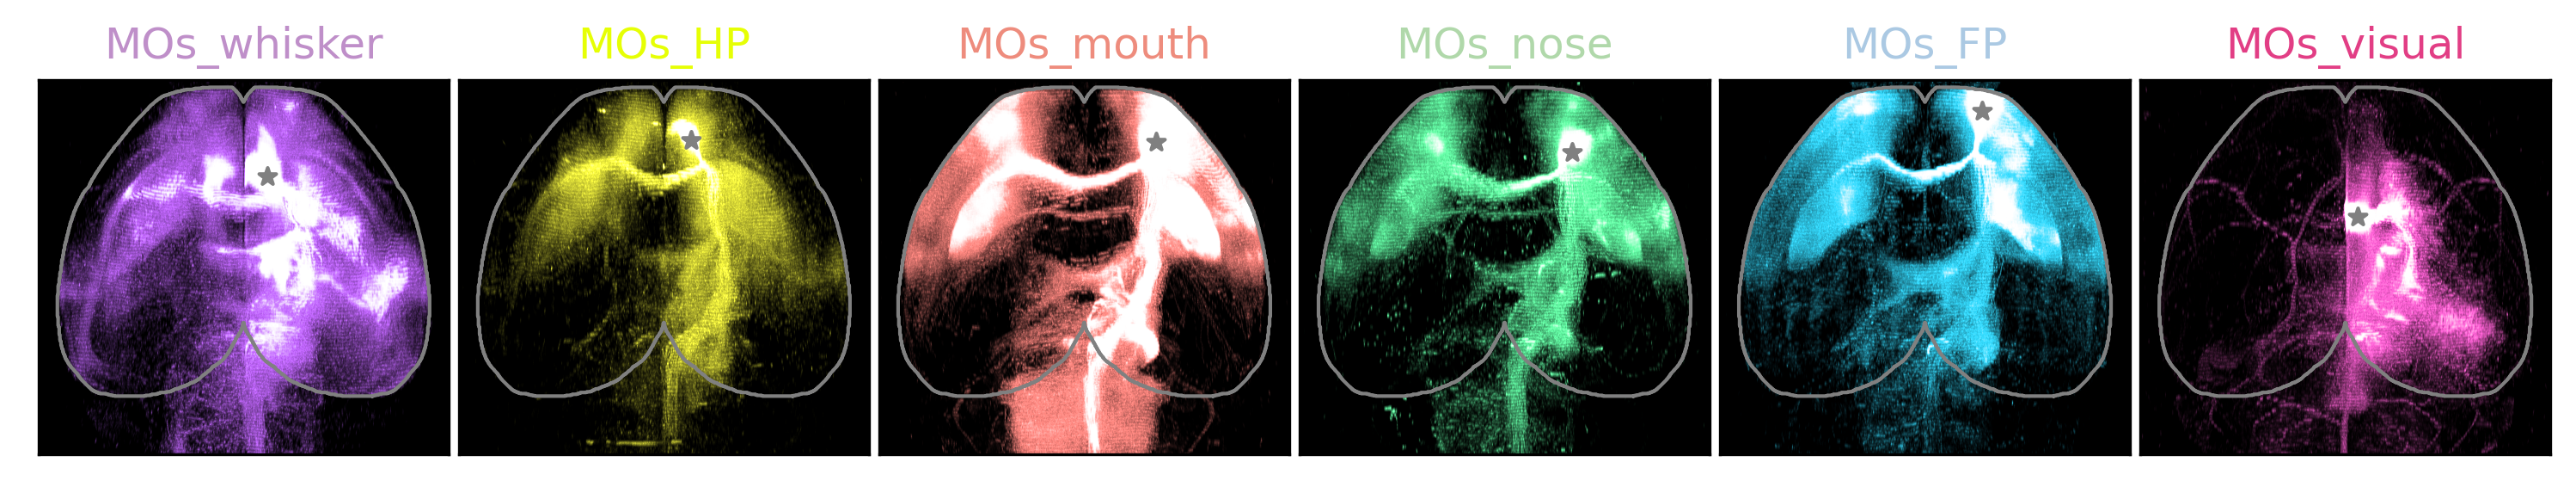

In [22]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=6

x_start = x_offset
for i_ax in range(6):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+7,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    

bdp_short_dict = {'LFP':'MOs_FP','LHP':'MOs_HP','LM':'MOs_mouth','LW':'MOs_whisker',
                  'LN':'MOs_nose','LV':'MOs_visual'}

dict_bdp_w_order = {'MOs_whisker':0,'MOs_HP':1,'MOs_mouth':2,'MOs_nose':3,'MOs_FP':4,'MOs_visual':5}

################################################
for i_bdp,bdp in enumerate(dict_bdp_w_order.keys()):
    ind_here = dict_bdp_w_order[bdp]
    # pd_mip = arr[:,:,:,ind_here].max(axis=1)
    pd_mip = dict_pd[bdp].max(axis=1)
    
    key = next((k for k, v in bdp_short_dict.items() if v == bdp), None)
    exec("ax{}.imshow(pd_mip*dict_scaling_factor[bdp],cmap=cmap_dict[key.replace('L','R')],vmin=0,vmax=1)".format(i_bdp))
    exec("ax{}.set_title(bdp,color=palatte_dict[key])".format(i_bdp))

    for contour in brain_contours:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=1)".format(i_bdp))
    exec("ax{}.scatter(dict_coord[bdp][1],dict_coord[bdp][0],marker='*', s=25, c='gray', zorder=2)".format(i_bdp))

        
for i_key in range(6):    
    exec("ax{}.set_ylim([1200,160])".format(i_key))
    
plt.savefig('figS5-M2-seeded-allen-connectivity-atlas-MIP.svg',format='svg',dpi=300)

# Merge and slice

In [176]:
dict_bdps_w_order = {'LW':0,'LV':5,'LN':3,'LM':2,'LHP':1,'LFP':4}


In [35]:
# Precompute MIPs for body parts and store in a dict
precomputed_mips = {}

for label in bdp_w_order:
    i_order = dict_bdps_w_order[label]
    vol_mip = np.mean(cortical_projection[..., i_order], axis=1)  # shape: (1320, 1140)
    precomputed_mips[label] = vol_mip


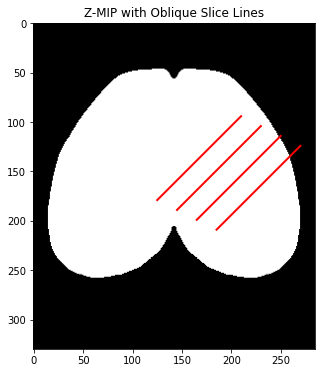

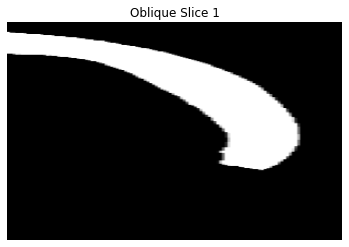

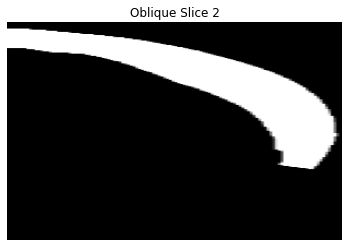

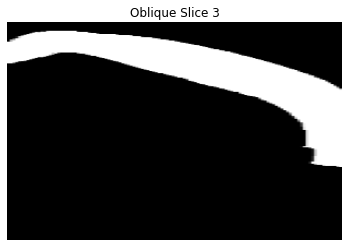

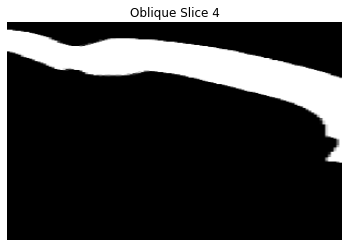

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 4
angle_deg = 45
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 120   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 10

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
mip = np.max(brain_mask_ds, axis=2)
plt.imshow(mip, cmap='gray')
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []

for i in range(num_slices):
    # Origin of oblique plane
    x0 = width - (i + 1) * slice_spacing - 80
    y0 = y_base - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    sampled = map_coordinates(brain_mask_ds, coords, order=1, mode='nearest')
    slice_img = sampled.reshape(plane_height, plane_width)
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img, cmap='gray', aspect='auto')
    plt.axis('off')


**Compose colors**

In [289]:
dict_scaling_factor= {'LW':2,'LV':1.5,'LN':1,'LM':1,'LFP':1,'LHP':1}
bdp_w_order = ['LV','LW','LN','LM']


In [290]:
import matplotlib.colors as mcolors

# Preprocess: convert hex palette to RGB array
# rgb_palette = {
#     k: np.array(mcolors.to_rgb(v), dtype=np.float32)
#     for k, v in palatte_dict.items()
# }

import colorsys

def boost_color(hex_color, sat_boost=1, light_boost=1):
    """Boosts saturation and lightness of a hex color"""
    rgb = mcolors.to_rgb(hex_color)
    h, l, s = colorsys.rgb_to_hls(*rgb)
    s = min(s * sat_boost, 1.0)
    l = min(l * light_boost, 1.0)
    boosted_rgb = colorsys.hls_to_rgb(h, l, s)
    return np.array(boosted_rgb, dtype=np.float32)

rgb_palette = {
    k: boost_color(v) for k, v in palatte_dict.items()
}


# Start with 80% white base from structural mask
brain_mask_norm = (brain_mask_ds / brain_mask_ds.max()).astype(np.float32)
composite_rgb = np.empty((*brain_mask_ds.shape, 3), dtype=np.float32)
# for c in range(3):
#     composite_rgb[..., c] = brain_mask_norm * 0.8  # white background


# STEP 1: Blend all projections with their unique scaling factor
for label in bdp_w_order:
    # Use label_r for both color and scale for consistency
    label_r = label.replace('L', 'R')
    color = rgb_palette[label_r]
    i_order = dict_bdps_w_order[label]
    scale = dict_scaling_factor.get(label, 1.0) # BUG FIX: Use label_r to get the scale

    vol = proj_channels_ds[..., i_order]  # (Y, Z, X)

    # Blend the scaled volume into the composite image
    for c in range(3):
        composite_rgb[..., c] += vol * color[c] * scale 
        
# STEP 2: Normalize the final result instead of clipping
if composite_rgb.max() > 0:
    composite_rgb /= composite_rgb.max()

# composite_rgb = np.clip(composite_rgb, 0, 1)
# gamma = 0.6  # <1.0 brightens midtones
# composite_rgb = composite_rgb ** gamma

brightness_boost = 1.5  # You can adjust this
composite_rgb *= brightness_boost
composite_rgb = np.clip(composite_rgb, 0, 1)


/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:12: RuntimeWarning: Mean of empty slice
  if sys.path[0] == '':


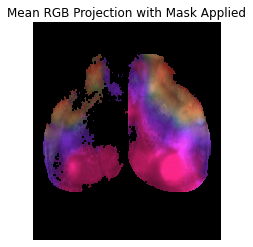

In [291]:
import numpy as np
import matplotlib.pyplot as plt

# Apply mask: compute mean across RGB channels
mask = composite_rgb.mean(axis=-1) < 0.2  # shape (330, 285, 200)

# Broadcast mask to last dimension (RGB)
composite_rgb_masked = composite_rgb.copy()
composite_rgb_masked[mask] = np.nan  # set all channels to nan where mask is True

# Compute nanmean along axis=2 (depth)
composite_rgb_mean = np.nanmean(composite_rgb_masked, axis=2)  # shape (330, 285, 3)

# Plot using imshow
plt.imshow(composite_rgb_mean)
plt.axis('off')
plt.title("Mean RGB Projection with Mask Applied")
plt.show()


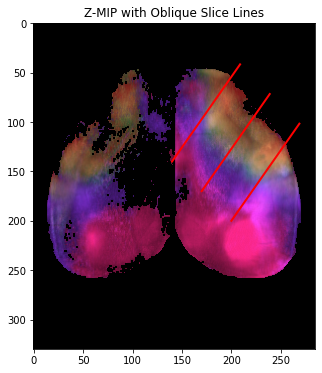

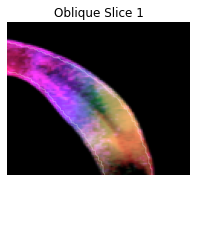

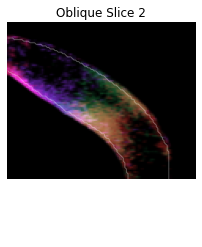

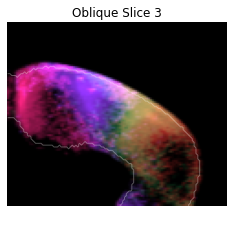

In [292]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 3
angle_deg = 55
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 120   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 30
x_step = 30

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
# mip = np.max(proj_channels_ds[...,0], axis=2)
# plt.imshow(mip, cmap='gray')
plt.imshow(composite_rgb_mean)
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []
contours = {}
for i in range(num_slices):
    # Origin of oblique plane
    x0 = 200 - i * x_step
    y0 = 200 - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    # --- START: MODIFIED CODE ---

    # Create the 3D coordinate array (y, x, z)
    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    
    # Sample each color channel independently from the 4D volume
    sampled_channels = []
    for channel_index in range(composite_rgb.shape[3]):
        # Sample from one 3D channel at a time
        sampled_channel = map_coordinates(composite_rgb[..., channel_index], coords, order=1, mode='nearest')
        sampled_channels.append(sampled_channel.reshape(plane_height, plane_width))

    # Stack the sampled channels back into an RGB image (height, width, 3)
    slice_img = np.stack(sampled_channels, axis=-1)
    
    # --- END: MODIFIED CODE ---
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

    
    # add cortical mask
    from skimage import measure

    # Resample mask with same coords
    sampled_mask = map_coordinates(brain_mask_ds.astype(np.float32), coords, order=1, mode='nearest')
    slice_mask = sampled_mask.reshape(plane_height, plane_width)

    # Binary threshold to define the brain region
    binary_mask = slice_mask > 0.5  # or try 0.1 depending on your mask scale

    # Find contours in the 2D slice (returns list of Nx2 arrays)
    contours[i] = measure.find_contours(binary_mask, level=0.5)


plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img[:100,:,:])
    plt.axis('off')
    for contour in contours[i]:
        plt.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)
        


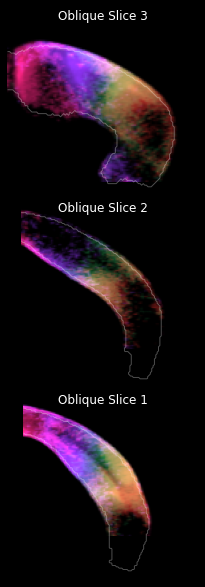

In [299]:
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'

# --- START: MODIFIED CODE ---

# Define the grid layout for the subplots (e.g., 2 rows, 2 columns for 4 slices)
nrows = 3
ncols = 1

# Create a figure and a set of subplots
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 8), facecolor='black')

# Flatten the axes array for easy iteration
axes = axes.flatten()

for i, slice_img in enumerate(oblique_slices):
    # Get the specific subplot axis for the current slice
    ax = axes[2-i]

    ax.set_title(f'Oblique Slice {i+1}', color='white',y=0.9)
    ax.imshow(slice_img[:110,:,:])
    ax.axis('off')

    # Plot contours on the corresponding subplot
    for contour in contours[i]:
        ax.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)

# Hide any unused subplots if the number of slices is less than the grid size
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

# Adjust layout to prevent titles from overlapping
plt.tight_layout(pad=0)

# Save the entire figure with 300 DPI resolution
# bbox_inches='tight' removes extra white space around the figure
plt.savefig('figS5-oblique_slices_comparison.svg', dpi=300, bbox_inches='tight')

# Display the figure
plt.show()

# --- END: MODIFIED CODE ---

# now forepaw and hindpaw

In [300]:
dict_scaling_factor= {'LFP':1.2,'LHP':0.7}
bdp_w_order = ['LFP','LHP']


In [301]:
# Start with 80% white base from structural mask
brain_mask_norm = (brain_mask_ds / brain_mask_ds.max()).astype(np.float32)
composite_rgb = np.empty((*brain_mask_ds.shape, 3), dtype=np.float32)
# for c in range(3):
#     composite_rgb[..., c] = brain_mask_norm * 0.8  # white background


# STEP 1: Blend all projections with their unique scaling factor
for label in bdp_w_order:
    # Use label_r for both color and scale for consistency
    label_r = label.replace('L', 'R')
    color = rgb_palette[label_r]
    i_order = dict_bdps_w_order[label]
    scale = dict_scaling_factor.get(label, 1.0) # BUG FIX: Use label_r to get the scale

    vol = proj_channels_ds[..., i_order]  # (Y, Z, X)

    # Blend the scaled volume into the composite image
    for c in range(3):
        composite_rgb[..., c] += vol * color[c] * scale 
        
# STEP 2: Normalize the final result instead of clipping
if composite_rgb.max() > 0:
    composite_rgb /= composite_rgb.max()

# composite_rgb = np.clip(composite_rgb, 0, 1)
# gamma = 0.6  # <1.0 brightens midtones
# composite_rgb = composite_rgb ** gamma

brightness_boost = 1.5  # You can adjust this
composite_rgb *= brightness_boost
composite_rgb = np.clip(composite_rgb, 0, 1)


/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:12: RuntimeWarning: Mean of empty slice
  if sys.path[0] == '':


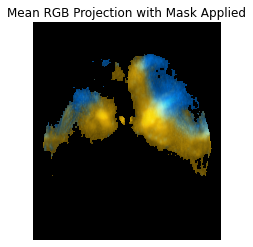

In [302]:
import numpy as np
import matplotlib.pyplot as plt

# Apply mask: compute mean across RGB channels
mask = composite_rgb.mean(axis=-1) < 0.2  # shape (330, 285, 200)

# Broadcast mask to last dimension (RGB)
composite_rgb_masked = composite_rgb.copy()
composite_rgb_masked[mask] = np.nan  # set all channels to nan where mask is True

# Compute nanmean along axis=2 (depth)
composite_rgb_mean = np.nanmean(composite_rgb_masked, axis=2)  # shape (330, 285, 3)

# Plot using imshow
plt.imshow(composite_rgb_mean)
plt.axis('off')
plt.title("Mean RGB Projection with Mask Applied")
plt.show()


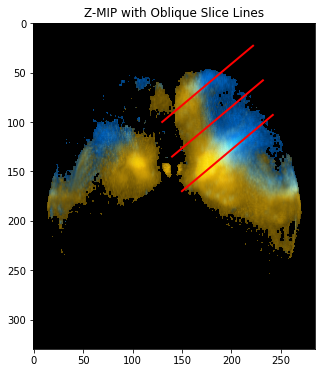

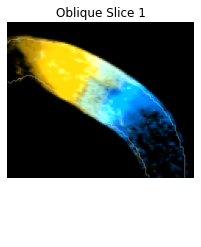

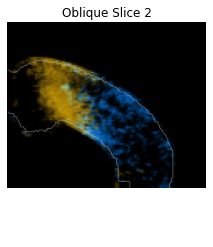

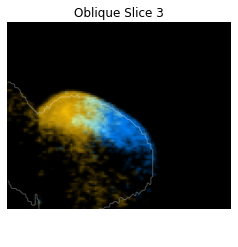

In [303]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 3
angle_deg = 40
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 120   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 35
x_step = 10

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
# mip = np.max(proj_channels_ds[...,0], axis=2)
# plt.imshow(mip, cmap='gray')
plt.imshow(composite_rgb_mean)
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []
contours = {}
for i in range(num_slices):
    # Origin of oblique plane
    x0 = 150 - i * x_step
    y0 = 170 - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    # --- START: MODIFIED CODE ---

    # Create the 3D coordinate array (y, x, z)
    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    
    # Sample each color channel independently from the 4D volume
    sampled_channels = []
    for channel_index in range(composite_rgb.shape[3]):
        # Sample from one 3D channel at a time
        sampled_channel = map_coordinates(composite_rgb[..., channel_index], coords, order=1, mode='nearest')
        sampled_channels.append(sampled_channel.reshape(plane_height, plane_width))

    # Stack the sampled channels back into an RGB image (height, width, 3)
    slice_img = np.stack(sampled_channels, axis=-1)
    
    # --- END: MODIFIED CODE ---
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

    
    # add cortical mask
    from skimage import measure

    # Resample mask with same coords
    sampled_mask = map_coordinates(brain_mask_ds.astype(np.float32), coords, order=1, mode='nearest')
    slice_mask = sampled_mask.reshape(plane_height, plane_width)

    # Binary threshold to define the brain region
    binary_mask = slice_mask > 0.5  # or try 0.1 depending on your mask scale

    # Find contours in the 2D slice (returns list of Nx2 arrays)
    contours[i] = measure.find_contours(binary_mask, level=0.5)


plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img[:100,:,:])
    plt.axis('off')
    for contour in contours[i]:
        plt.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)

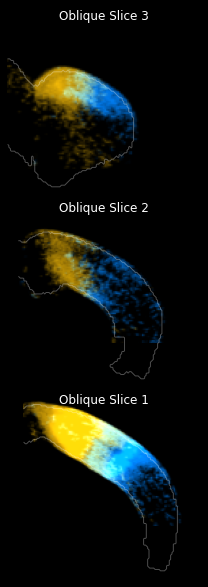

In [304]:



# --- START: MODIFIED CODE ---

# Define the grid layout for the subplots (e.g., 2 rows, 2 columns for 4 slices)
nrows = 3
ncols = 1

# Create a figure and a set of subplots
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 8), facecolor='black')

# Flatten the axes array for easy iteration
axes = axes.flatten()

for i, slice_img in enumerate(oblique_slices):
    # Get the specific subplot axis for the current slice
    ax = axes[2-i]

    ax.set_title(f'Oblique Slice {i+1}', color='white',y=0.9)
    ax.imshow(slice_img[:100,:,:])
    ax.axis('off')

    # Plot contours on the corresponding subplot
    for contour in contours[i]:
        ax.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)

# Hide any unused subplots if the number of slices is less than the grid size
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.rcParams['svg.fonttype'] = 'none'
# Adjust layout to prevent titles from overlapping
plt.tight_layout(pad=0)

# Save the entire figure with 300 DPI resolution
# bbox_inches='tight' removes extra white space around the figure
plt.savefig('figS5-oblique_slices_comparison_FPHP.svg', dpi=300, bbox_inches='tight')

# Display the figure
plt.show()

# --- END: MODIFIED CODE ---




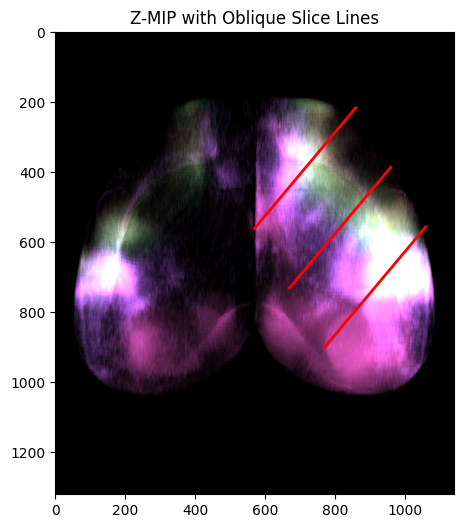

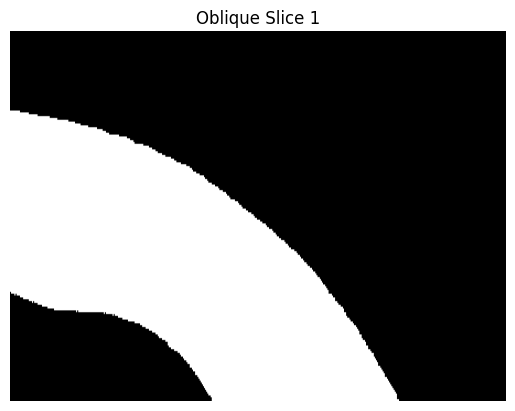

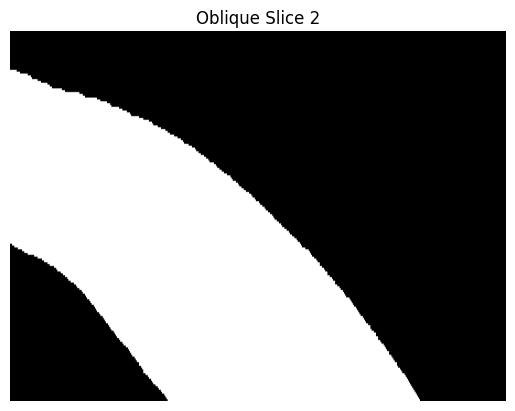

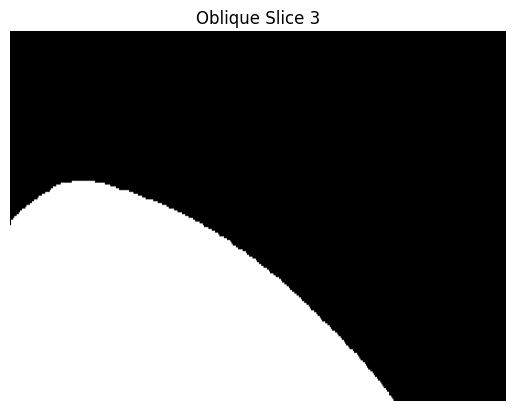

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

brain_mask_ds = cortical_mask.transpose((0,2,1))
# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 3
angle_deg = 50
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 450   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 170
x_step = 100

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
# mip = np.max(brain_mask_ds, axis=2)
# plt.imshow(mip, cmap='gray')
plt.imshow(canvas_rgb)
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []

for i in range(num_slices):
    # Origin of oblique plane
    x0 = 770 - i * x_step
    y0 = 900 - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    sampled = map_coordinates(brain_mask_ds, coords, order=1, mode='nearest')
    slice_img = sampled.reshape(plane_height, plane_width)
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img, cmap='gray', aspect='auto')
    plt.axis('off')


In [16]:
# ss = cortical_projection.shape
# composite_rgb = np.zeros((ss[0],ss[2],ss[1], 3), dtype=np.float32)


# for label in bdp_w_order:
#     i_order = dict_bdps_w_order[label]
#     vol = cortical_projection[..., i_order].transpose((0,2,1)) 

#     # Normalize (if needed) to [0, 1] — or scale using your dict_scaling_factor
#     vol_scaled = vol / 65536.0

#     # Apply custom colormap to each voxel
#     cmap = cmap_dict[label.replace('L', 'R')]
#     rgba = cmap(vol_scaled)  # shape: (Y, X, Z, 4)
#     rgb = rgba[..., :3] * rgba[..., 3:]  # premultiplied alpha

#     composite_rgb += rgb

In [23]:
brain_mask_ds = cortex_mask.transpose((0,2,1))

In [24]:
import matplotlib.colors as mcolors

# Preprocess: convert hex palette to RGB array
rgb_palette = {
    k: np.array(mcolors.to_rgb(v), dtype=np.float32)
    for k, v in palatte_dict.items()
}

# Start with 80% white base from structural mask
brain_mask_norm = (brain_mask_ds / brain_mask_ds.max()).astype(np.float32)
composite_rgb = np.empty((*brain_mask_ds.shape, 3), dtype=np.float32)
for c in range(3):
    composite_rgb[..., c] = brain_mask_norm * 0.8  # white background

# Blend in each projection
for label in bdp_w_order:
    label_r = label.replace('L', 'R')
    color = rgb_palette[label_r]
    i_order = dict_bdps_w_order[label]
    scale = dict_scaling_factor.get(label_r, 1.0)

    vol = cortical_projection[..., i_order].transpose((0, 2, 1))  # (Y, Z, X)
    vol_scaled = np.clip(vol * scale, 0, 1).astype(np.float32)     # ∈ [0, 1]

    # Blend directly into RGB channels
    for c in range(3):
        composite_rgb[..., c] += vol_scaled * color[c]


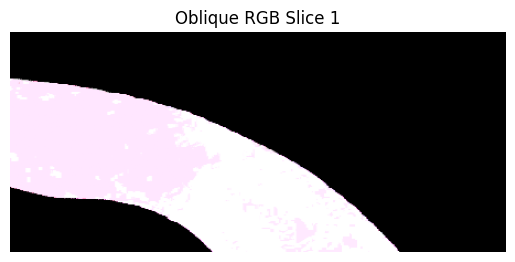

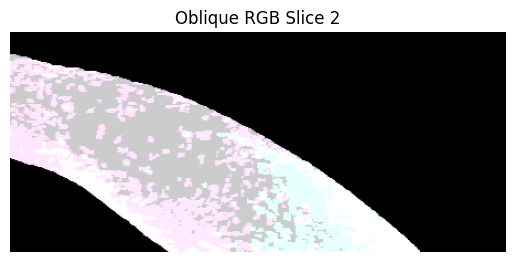

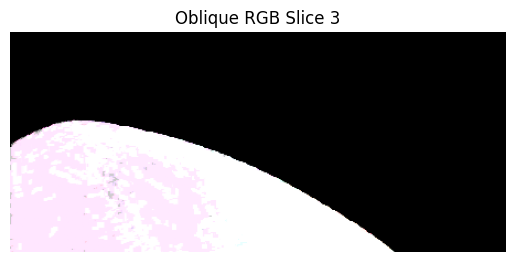

In [30]:
# Assume: composite_rgb.shape = (Y, X, Z, 3)
# composite_rgb = np.stack([channel_r, channel_g, channel_b], axis=-1)  # just placeholder
# composite_rgb = composite_rgb.transpose((0, 2, 1, 3))  # to match brain_mask_ds (Y, X, Z, C)

rgb_oblique_slices = []
num_slices = 3
for i in range(num_slices):
    x0 = 770 - i * x_step
    y0 = 900 - i * y_step
    z0 = 0

    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])

    # Slice each color channel
    rgb_slice = []
    for c in range(3):
        channel_data = composite_rgb[..., c]
        sampled = map_coordinates(channel_data, coords, order=1, mode='nearest')
        rgb_slice.append(sampled.reshape(plane_height, plane_width))

    rgb_slice = np.stack(rgb_slice, axis=-1)  # (H, W, 3)
    rgb_oblique_slices.append(np.clip(rgb_slice, 0, 1))  # ensure displayable range

# --- Display the RGB slices
for i, rgb_img in enumerate(rgb_oblique_slices):
    plt.figure()
    plt.title(f'Oblique RGB Slice {i+1}')
    plt.imshow(rgb_img)
    plt.axis('off')







# M2

In [17]:
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/wild-type-M2")

need to see coordinates

In [18]:
MOs,info = mcc.get_structure_mask(993)

2025-07-08 13:08:45,285 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://download.alleninstitute.org/informatics-archive/current-release/mouse_ccf/annotation/ccf_2017/structure_masks/structure_masks_10/structure_993.nrrd


In [27]:
results_coord={}
results_coord['HP'] = (290,610)
results_coord['FP'] = (237,700)
results_coord['mouth']=(356, 820)
results_coord['nose']=(360, 740)
results_coord['whisker'] = (394, 656.989247311828)
results_coord['visual'] = (506, 605.939393939394)
bodyparts = results_coord.keys()
bdp_short_dict_2 = {"whisker":'RW', "mouth":'RM', "nose":'RN', "FP":'RFP', "HP":'RHP',
                    "visual":'RV'}

In [43]:
experiment_ids_MOs = {
    "MOs_whisker": 141603190,
    "MOs_FP": 157710335,
    # "MOs_HP": 112952510,
    "MOs_nose": 585025284,
    "MOs_HP": 100141454,

}

In [20]:
# Get ALL experiments as DataFrame
all_experiments = mcc.get_experiments(dataframe=True)
print(f"{len(all_experiments)} total experiments")

2992 total experiments


Found 4 experiments.


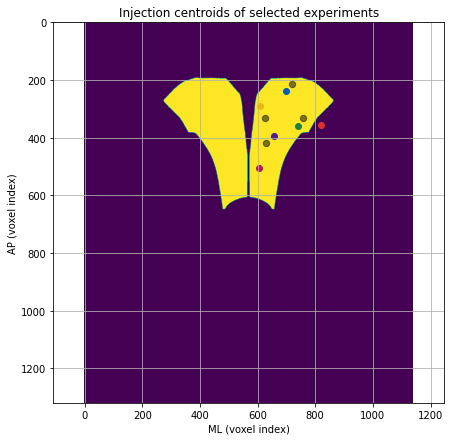

In [44]:
import matplotlib.pyplot as plt

# Your list of experiment IDs
experiment_ids = experiment_ids_MOs.values()

# Filter DataFrame to only these experiments
selected_experiments = all_experiments.loc[experiment_ids]

# Confirm they are all found
print(f"Found {len(selected_experiments)} experiments.")

# Extract coordinates
ap_um = selected_experiments["injection_x"].values
ml_um = selected_experiments["injection_z"].values

# Convert µm to voxel indices in your MIP matrix (voxel size = 10um)
ap_voxels = ap_um / 10
ml_voxels = ml_um / 10

# Plot
plt.figure(figsize=(7,7))

# Optional: background (e.g., MIP of your mask)
# plt.imshow(MIP_surface, cmap="gray", alpha=0.3)
# plt.imshow(results_blob[bdp]==1)
plt.imshow(np.squeeze(np.max(MOs,1)))
plt.scatter(ml_voxels, ap_voxels, c='black', s=40, edgecolors='k',alpha=0.5)
for bdp in bodyparts:
    plt.scatter(results_coord[bdp][1],results_coord[bdp][0],c=palatte_dict[bdp_short_dict_2[bdp]])

# plt.gca().invert_yaxis()  # So anterior is top
plt.xlabel("ML (voxel index)")
plt.ylabel("AP (voxel index)")
plt.title("Injection centroids of selected experiments")
plt.grid(True)
plt.axis("equal")
plt.show()


In [47]:
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/wild-type-M2")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

2992 total experiments


In [48]:
dict_pd = {}
dict_pd_info = {}
dict_ind = {}
dict_ind_info = {}
for key in experiment_ids_MOs:
    experiment_id = experiment_ids_MOs[key]
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    

2025-07-08 13:58:33,810 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/141603190?image=projection_density&resolution=10
2025-07-08 13:59:45,970 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/141603190?image=injection_density&resolution=10
2025-07-08 14:00:08,839 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/157710335?image=projection_density&resolution=10
2025-07-08 14:01:09,283 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/157710335?image=injection_density&resolution=10
2025-07-08 14:01:31,405 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/585025284?image=projection_density&resolution=10
2025-07-08 14:02:19,250 allensdk.api.api.retrieve_file_ov

In [49]:
for key in dict_pd.keys():
    print(dict_pd[key].shape)

(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)


In [50]:
from save_dict_to_hdf5 import *
save_dict_to_hdf5(dict_pd,result_path+'/wild_type_M2.mat')

2992 total experiments


# M2 but not wild type

In [52]:
dict_experiment_ids_M2_extra = {
                      'MOs_mouth':166082128, #Rbp4-Cre-113
                      'MOs_visual':158018630 #Gng7-Cre-971
}



In [54]:
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/extra-M2")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

2992 total experiments


In [55]:
dict_pd = {}
dict_pd_info = {}
dict_ind = {}
dict_ind_info = {}
for key in dict_experiment_ids_M2_extra:
    experiment_id = dict_experiment_ids_M2_extra[key]
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    

2025-07-08 14:27:17,816 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/166082128?image=projection_density&resolution=10
2025-07-08 14:28:20,212 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/166082128?image=injection_density&resolution=10
2025-07-08 14:28:41,194 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/158018630?image=projection_density&resolution=10
2025-07-08 14:29:27,507 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/158018630?image=injection_density&resolution=10


In [56]:
from save_dict_to_hdf5 import *
save_dict_to_hdf5(dict_pd,result_path+'/other_types_M2.mat')

In [58]:
import scipy
scipy.io.savemat('other_types_M2.mat', dict_pd, format='7.3')

ValueError: Format should be '4' or '5'

# END HERE

(1200.0, 180.0)

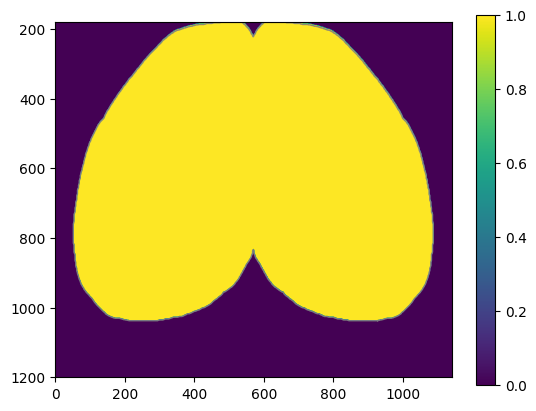

In [26]:
# in addition to the annotation volume, you can get binary masks for individual structures
# in this case, we'll get one for the isocortex
cortex_mask, cm_info = mcc.get_structure_mask(315)

cortex_mask_mip = cortex_mask.max(axis=1)

from skimage import measure
brain_contours = measure.find_contours(cortex_mask_mip>0.5, level=0.5)

    
plt.imshow(cortex_mask_mip)
plt.colorbar()
for contour in brain_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.9)
# plt.xlim([20,436])
plt.ylim([1200,160])

In [14]:
cortex_mask_mip.shape

(1320, 1140)

In [15]:
dict_coord={}
dict_S1_contour = {}
from scipy.ndimage import center_of_mass
for key in dict_experiment_id:
    dict_coord[key] = center_of_mass(dict_ind[key].max(axis=1))
    S1_contours = measure.find_contours(dict_ind[key].max(axis=1)>0.5, level=0.5)
    dict_S1_contour[key] = S1_contours

In [17]:
from matplotlib.colors import LinearSegmentedColormap
# def make_custom_cmap(hex_color, name):
#     return LinearSegmentedColormap.from_list(name, ['black', hex_color])


from matplotlib.colors import LinearSegmentedColormap, to_rgb

def make_dynamic_cmap(hex_color, name):
    base_rgb = to_rgb(hex_color)
    
    # Add a middle point (scaled up to boost intensity)
    # boosted = tuple(min(1, c * 2) for c in base_rgb)
    boost = 2
    boosted = tuple(min(1.0, c * boost + 0.2 * (1 - c)) for c in base_rgb)
    return LinearSegmentedColormap.from_list(name, ['black', boosted, 'white'])



cmap_dict = {key: make_dynamic_cmap(color, key) for key, color in palatte_dict.items()}


In [23]:
dict_scaling_factor= {'LW':0.7,
                'LV':0.7,
                     'LN':0.5,
                     'LM':0.6,
                     'LFP':0.8,
                     'LHP':0.65}

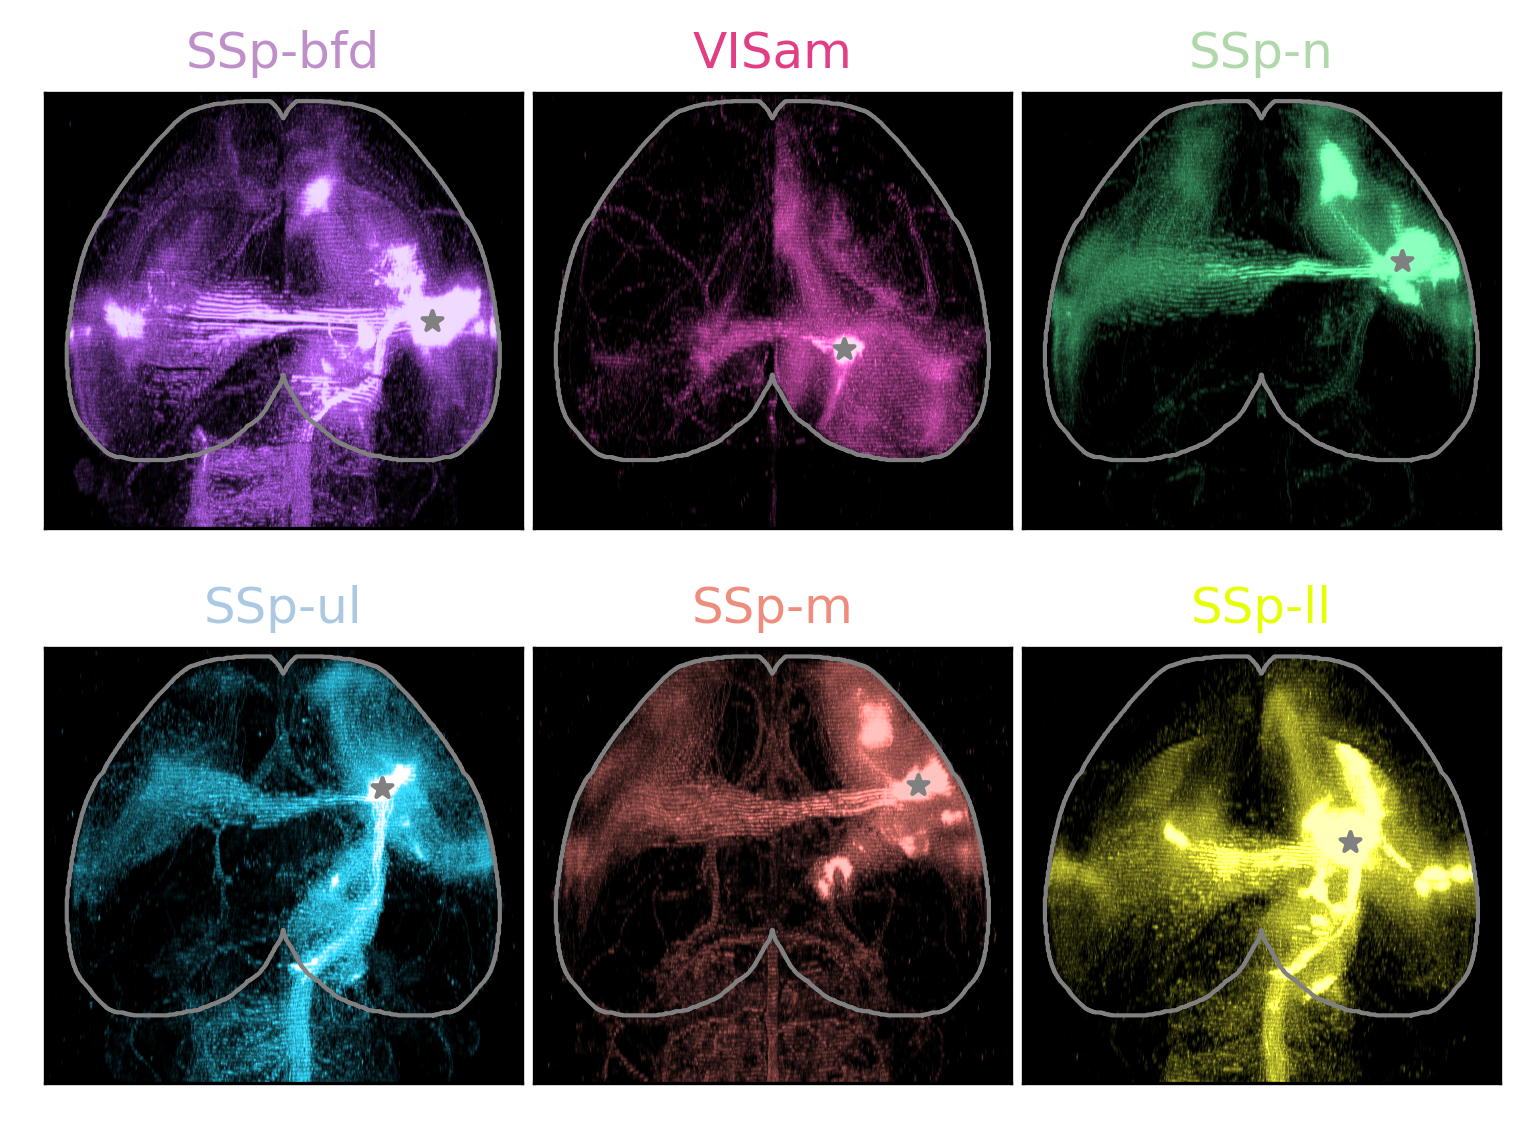

In [27]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=6

x_start = x_offset
for i_ax in range(3):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+7,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
x_start = x_offset
for i_ax in range(3,6):
    exec("ax{} = fig.add_subplot(gs[y_offset+8:y_offset+15,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))    
    


bdp_short_dict = {'LFP':'SSp-ul','LHP':'SSp-ll','LM':'SSp-m','LW':'SSp-bfd',
                  'LN':'SSp-n','LV':'VISam'}



################################################
for i_key,key in enumerate(dict_experiment_id):
    pd_mip = dict_pd[key].max(axis=1)
    exec("ax{}.imshow(pd_mip*dict_scaling_factor[key],cmap=cmap_dict[key.replace('L','R')],vmin=0,vmax=0.8)".format(i_key))
    exec("ax{}.set_title(bdp_short_dict[key],color=palatte_dict[key])".format(i_key))
    # exec("ax{}.colorbar()".format(i_key))
    for contour in brain_contours:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=1)".format(i_key))
    exec("ax{}.scatter(dict_coord[key][1],dict_coord[key][0],marker='*', s=25, c='gray', zorder=2)".format(i_key))

        
for i_key in range(6):    
    exec("ax{}.set_ylim([1200,160])".format(i_key))
    
plt.savefig('figS5-M2-S1-allen-connectivity-atlas-MIP.svg',format='svg',dpi=300)

In [45]:
dict_pd['brain_mask'] = cortex_mask

In [ ]:
with h5py.File("dict_pd.h5", "w") as h5f:
    for key, array in dict_pd.items():
        h5f.create_dataset(key, data=array)  # no compression
